# Automated Feature Extraction

Send the Taj Mahal photo to a commercial image analysis service, and within a second it returns
two kinds of results (Figure 9.10 of the book). The perception branch lists the dominant colors
with their shares and measures brightness, sharpness, and contrast. The recognition branch lists
labels with confidence values. This notebook follows the book section *Automated Feature
Extraction* and builds both branches on our own. We climb the abstraction ladder from raw pixels
to perceptual features, train a classifier that turns audio features into labels, and let a
pretrained neural network compute learned features and labels.

**Learning goals:**
- See why raw data helps little with search: two photos of one building share almost no pixel values
- Compute perceptual features: dominant colors, and a color histogram as the image counterpart of a term vector
- Test which invariances a color histogram has and which it lacks
- See that perceptual similarity is not semantic similarity
- Separate speech from music with two frame features and a decision tree
- Compare the learned features of a neural network with perceptual features, and read its labels as claims

**Prerequisites:** Chapter 1 (term vectors), Chapter 2 (confusion matrix), Chapter 6 (nearest-neighbor
search), demo ch09-01

**Data:** nine photos and six audio excerpts from Wikimedia Commons under Creative Commons and
public-domain licenses; `data/ch09/SOURCES.md` lists authors and licenses. The neural network is
ResNet-50 (`microsoft/resnet-50`, about 100 MB on the first run).

## Setup

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image, ImageEnhance
from scipy.ndimage import laplace
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier, export_text

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # quiet model downloads
os.environ["HF_HUB_VERBOSITY"] = "error"
import torch
from transformers import AutoImageProcessor, ResNetForImageClassification
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

from shared.display import print_table, display_md
from ch09_media import AUDIO, IMAGES, load_audio, load_images

images = load_images()
taj = Image.open("data/images/taj_mahal.jpg").convert("RGB")    # the photo of demo ch09-01

The collection holds nine photos. Most of them come in pairs of the same kind; the red car and
the sunset share colors but nothing else.

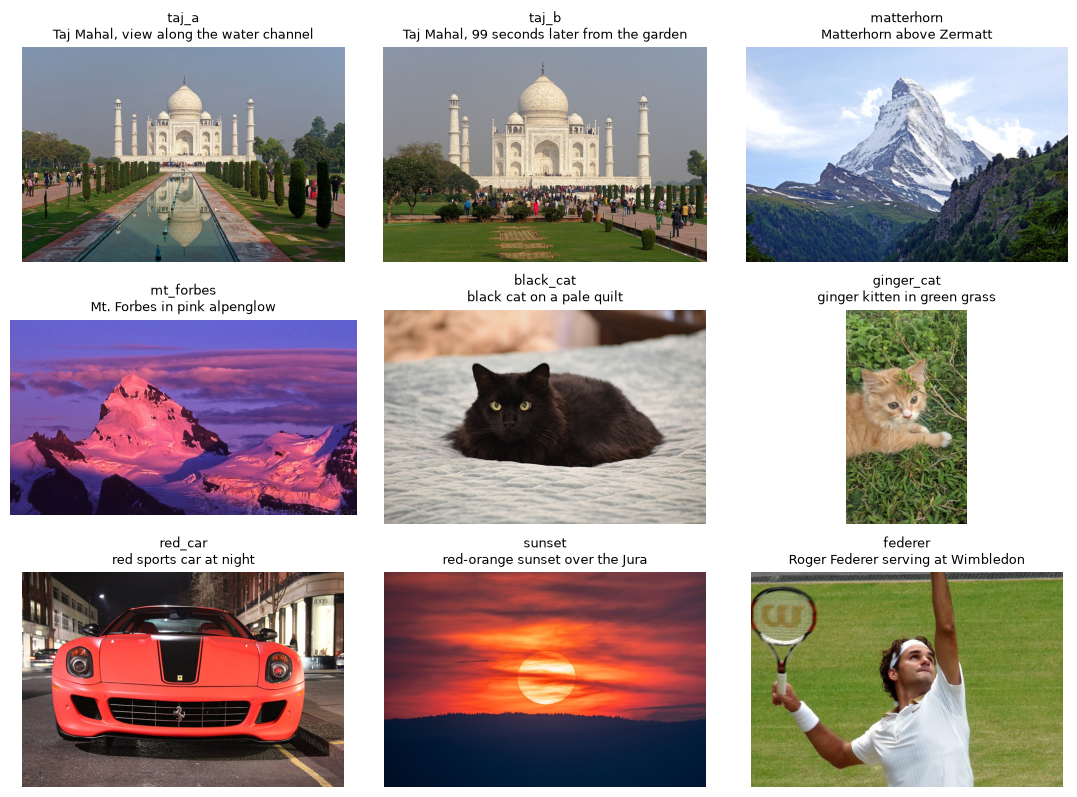

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, (name, img) in zip(axes.ravel(), images.items()):
    ax.imshow(img)
    ax.set_title(f"{name}\n{IMAGES[name][1]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 1. Perception: What a Service Measures

The perception branch of Figure 9.10 does not interpret the photo. It summarizes the colors and
measures the quality of the signal. We do the same for the Taj Mahal photo of demo ch09-01.
k-means groups the pixel colors into five clusters: it assigns each pixel to the nearest of five
centers and moves each center to the mean of its pixels, until the centers settle. The share of
each cluster is the share of the image in that color. A lookup in the CSS color table gives each cluster a name.

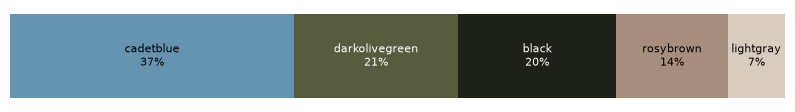

| Perception | Value |
|---|---|
| dominant color 1 | cadetblue, 37% |
| dominant color 2 | darkolivegreen, 21% |
| dominant color 3 | black, 20% |
| dominant color 4 | rosybrown, 14% |
| dominant color 5 | lightgray, 7% |
| brightness | 44% |
| contrast | 21% |
| sharpness | 1065 |

In [3]:
CSS = {name: np.array(mcolors.to_rgb(hex_)) * 255 for name, hex_ in mcolors.CSS4_COLORS.items()}

def css_name(rgb):
    """Name of the CSS color closest to an RGB triple."""
    return min(CSS, key=lambda name: ((CSS[name] - rgb) ** 2).sum())

def kmeans(X, k, iters=30, seed=0):
    """Lloyd's algorithm: assign each point to its nearest center, move each center to the mean of its points."""
    centers = X[np.random.default_rng(seed).choice(len(X), k, replace=False)]
    for _ in range(iters):
        labels = ((X[:, None, :] - centers[None]) ** 2).sum(axis=-1).argmin(axis=1)
        centers = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centers[j] for j in range(k)])
    return centers, labels

def dominant_colors(img, k=5, sample=50_000, seed=0):
    """k-means over a sample of the pixel colors: (name, RGB, share of pixels) per cluster, largest first."""
    px = np.asarray(img).reshape(-1, 3).astype(float)
    centers, labels = kmeans(px[np.random.default_rng(seed).choice(len(px), sample, replace=False)], k, seed=seed)
    shares = np.bincount(labels, minlength=k) / len(labels)
    return [(css_name(centers[i]), centers[i], shares[i]) for i in np.argsort(-shares)]

def quality(img):
    """Brightness and contrast (mean and std of the gray values), sharpness (variance of the Laplacian)."""
    gray = np.asarray(img.convert("L"), dtype=float)
    return gray.mean() / 255, gray.std() / 255, laplace(gray).var()

colors = dominant_colors(taj)
brightness, contrast, sharpness = quality(taj)

fig, ax = plt.subplots(figsize=(10, 1.2))
left = 0
for name, rgb, share in colors:
    ax.barh(0, share, left=left, color=rgb / 255)
    ax.text(left + share / 2, 0, f"{name}\n{share:.0%}", ha="center", va="center", fontsize=8,
            color="black" if rgb.mean() > 110 else "white")
    left += share
ax.set_xlim(0, 1)
ax.axis("off")
plt.show()

display_md(
    f"| Perception | Value |\n|---|---|\n"
    + "".join(f"| dominant color {i + 1} | {name}, {share:.0%} |\n" for i, (name, _, share) in enumerate(colors))
    + f"| brightness | {brightness:.0%} |\n| contrast | {contrast:.0%} |\n| sharpness | {sharpness:.0f} |"
)

Every value describes how the photo looks; none says what it shows. The service in the book
reports "steel blue" and "light beige" for its Taj Mahal photo; our photo, taken on another day,
has its own shares.

## 2. The Raw Level: Same Building, Different Numbers

The raw level is the file as stored. It preserves the content for display but helps little with
search, because similar content rarely means similar raw data. The photos `taj_a` and `taj_b`
were taken by the same photographer with the same camera, 99 seconds apart, a few steps from
each other. We count how many pixels agree exactly, and how many agree within 10 intensity
levels per channel.

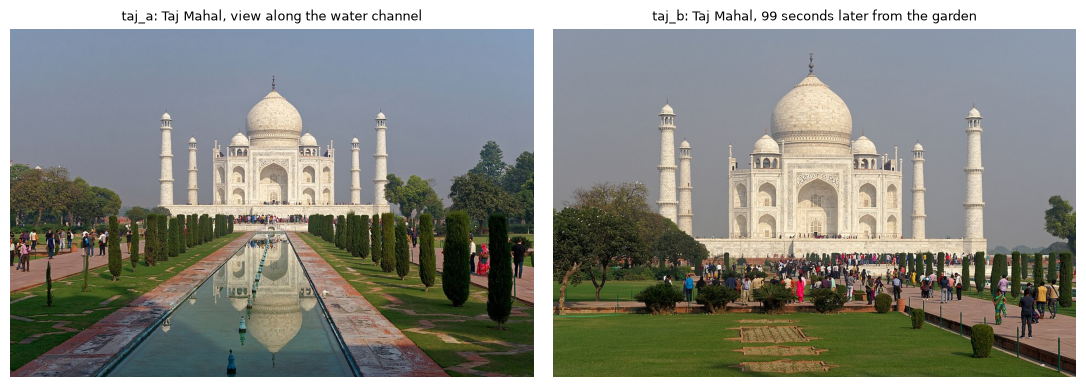

| Pixels compared | 960 · 638 = 612,480 |
|---|---|
| identical RGB values | 23 pixels (0.004%) |
| within ±10 per channel | 28.9% |

In [4]:
a = np.asarray(images["taj_a"], dtype=int)
b = np.asarray(images["taj_b"].resize(images["taj_a"].size), dtype=int)

same = (a == b).all(axis=2)
close = (np.abs(a - b) <= 10).all(axis=2).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name in zip(axes, ["taj_a", "taj_b"]):
    ax.imshow(images[name])
    ax.set_title(f"{name}: {IMAGES[name][1]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

display_md(
    f"| Pixels compared | {a.shape[1]} · {a.shape[0]} = {a.shape[0] * a.shape[1]:,} |\n|---|---|\n"
    f"| identical RGB values | {same.sum():,} pixels ({same.mean():.3%}) |\n"
    f"| within ±10 per channel | {close:.1%} |"
)

Both photos show the same building in the same light, yet only a handful of pixels have identical
values, and even with a tolerance of 10 levels per channel fewer than a third agree. A search
that compares raw data would not relate them.

## 3. Perceptual Features: The Color Histogram

A color histogram counts how many pixels fall into each of a fixed set of color bins. We split
each of the three channels into 4 ranges, which gives 4 · 4 · 4 = 64 color cells. The book calls
the histogram the image counterpart of a term vector: the bins play the role of terms, and the
pixel counts play the role of term frequencies. We divide by the number of pixels, so images of
different sizes become comparable.

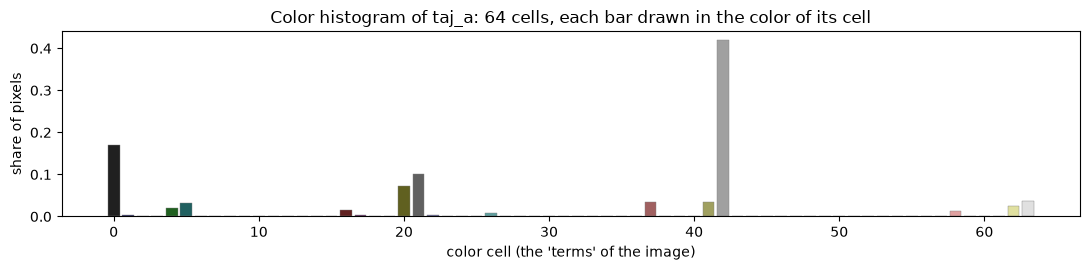

Nonzero cells: **40 of 64**; the three largest cover 69% of the pixels. The histograms of `taj_a` and `taj_b` have **82%** of their pixels in common.

In [5]:
BINS = 4                                   # ranges per channel: 4 · 4 · 4 = 64 color cells
STEP = 256 // BINS
CELL_RGB = np.array([[r, g, b] for r in range(BINS) for g in range(BINS) for b in range(BINS)]) * STEP + STEP // 2

def color_histogram(img):
    """Share of the pixels in each of the BINS**3 color cells."""
    q = np.asarray(img.convert("RGB")) // STEP
    cell = (q[..., 0] * BINS + q[..., 1]) * BINS + q[..., 2]
    counts = np.bincount(cell.ravel(), minlength=BINS ** 3)
    return counts / counts.sum()

def intersection(h1, h2):
    """Histogram intersection: the share of pixels that the two histograms have in common."""
    return float(np.minimum(h1, h2).sum())

hists = {name: color_histogram(img) for name, img in images.items()}

h = hists["taj_a"]
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(range(len(h)), h, color=CELL_RGB / 255, edgecolor="gray", linewidth=0.3)
ax.set_xlabel("color cell (the 'terms' of the image)")
ax.set_ylabel("share of pixels")
ax.set_title("Color histogram of taj_a: 64 cells, each bar drawn in the color of its cell")
plt.tight_layout()
plt.show()

display_md(
    f"Nonzero cells: **{(h > 0).sum()} of {len(h)}**; the three largest cover "
    f"{np.sort(h)[-3:].sum():.0%} of the pixels. The histograms of `taj_a` and `taj_b` have "
    f"**{intersection(hists['taj_a'], hists['taj_b']):.0%}** of their pixels in common."
)

The comparison that failed on raw pixels succeeds on histograms. Perceptual features invert the
argument of the raw level: they assume that similar statistics of the signal indicate similar
content.

### Invariances

Good perceptual features stay stable under variations that human perception ignores. We change
`taj_a` in five ways and compare each version with the original, once by identical pixels and
once by histogram intersection. Where the sizes differ, we compare the overlapping or rescaled
part.

In [6]:
def compare(x, y):
    """Share of identical pixels and histogram intersection of two images of the same size."""
    ax, ay = np.asarray(x), np.asarray(y)
    return (ax == ay).all(axis=2).mean(), intersection(color_histogram(x), color_histogram(y))

def center(img, frac=0.7):
    """Central crop that removes the corners a rotation leaves empty."""
    w, h = img.size
    dx, dy = int(w * (1 - frac) / 2), int(h * (1 - frac) / 2)
    return img.crop((dx, dy, w - dx, h - dy))

img = images["taj_a"]
w, h = img.size
noise = np.random.default_rng(0).normal(0, 20, np.asarray(img).shape)
variants = {
    "translation: camera moved 24 pixels": (img.crop((0, 0, w - 24, h - 24)), img.crop((24, 24, w, h))),
    "rotation: 10 degrees": (center(img), center(img.rotate(10, resample=Image.BICUBIC))),
    "scale: thumbnail of 1/8 size": (img, img.resize((w // 8, h // 8)).resize((w, h), Image.NEAREST)),
    "noise: Gaussian, sigma 20": (img, Image.fromarray(np.clip(np.asarray(img) + noise, 0, 255).astype(np.uint8))),
    "lighting: 40% darker": (img, ImageEnhance.Brightness(img).enhance(0.6)),
}
rows = [[change, *compare(x, y)] for change, (x, y) in variants.items()]
print_table(rows, headers=["Change", "Identical pixels", "Histogram intersection"], floatfmt=("", ".1%", ".0%"))

| Change                              |   Identical pixels |   Histogram intersection |
|:------------------------------------|-------------------:|-------------------------:|
| translation: camera moved 24 pixels |               0.5% |                      96% |
| rotation: 10 degrees                |               0.3% |                      97% |
| scale: thumbnail of 1/8 size        |              14.4% |                      96% |
| noise: Gaussian, sigma 20           |               0.0% |                      67% |
| lighting: 40% darker                |               0.0% |                      41% |

The histogram ignores where a color sits, so translation, rotation, and scale change it little,
while almost every pixel value changes. Noise moves about a third of the pixels into
neighboring cells.
Lighting is the weak point: a darker photo moves most pixels into darker cells, although a person
sees the same building. The chapter on visual features shows color spaces that separate
brightness from color.

## 4. Perceptual Similarity Is Not Semantic Similarity

The book warns: a red car and a sunset have similar color histograms, while a black cat on a
white carpet and a ginger cat on a green lawn have very different ones. Our collection contains
these cases. We compare every pair by histogram intersection.

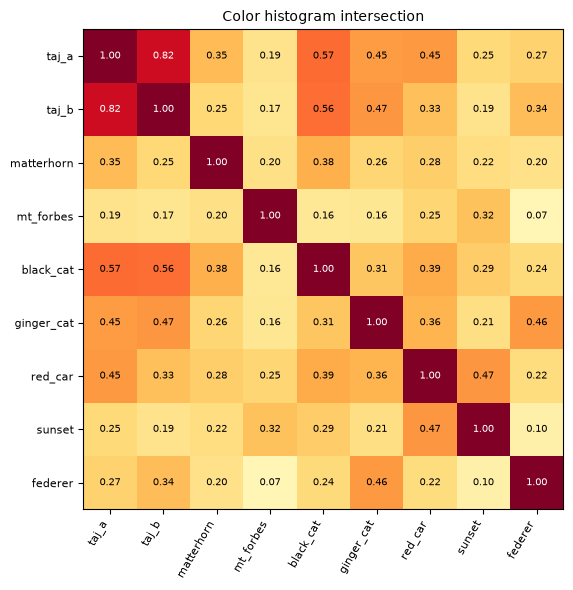

| Image 1    | Image 2    | Content          |   Histogram intersection |
|:-----------|:-----------|:-----------------|-------------------------:|
| red_car    | sunset     | car and sunset   |                     0.47 |
| black_cat  | ginger_cat | two cats         |                     0.31 |
| black_cat  | taj_a      | cat and building |                     0.57 |
| matterhorn | mt_forbes  | two mountains    |                     0.20 |

In [7]:
names = list(images)

def show_matrix(S, title, ax, fmt="{:.2f}"):
    """Heat map of a similarity matrix with the values printed in the cells."""
    ax.imshow(S, cmap="YlOrRd", vmin=0, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, fmt.format(S[i, j]), ha="center", va="center", fontsize=7,
                    color="white" if S[i, j] > 0.6 else "black")
    ax.set_title(title, fontsize=10)

S_hist = np.array([[intersection(hists[p], hists[q]) for q in names] for p in names])

fig, ax = plt.subplots(figsize=(7, 6))
show_matrix(S_hist, "Color histogram intersection", ax)
plt.tight_layout()
plt.show()

pair = lambda p, q: S_hist[names.index(p), names.index(q)]
print_table([
    ["red_car", "sunset", "car and sunset", pair("red_car", "sunset")],
    ["black_cat", "ginger_cat", "two cats", pair("black_cat", "ginger_cat")],
    ["black_cat", "taj_a", "cat and building", pair("black_cat", "taj_a")],
    ["matterhorn", "mt_forbes", "two mountains", pair("matterhorn", "mt_forbes")],
], headers=["Image 1", "Image 2", "Content", "Histogram intersection"], floatfmt=("", "", "", ".2f"))

The red car and the sunset share more colors than the two cats do. The black cat on its pale
quilt is closer to the white marble of the Taj Mahal than to the ginger kitten in the grass. The
two mountains, one in daylight and one in pink alpenglow, have little in common. Perceptual
features find content that looks similar. That is useful for queries by example and for near
duplicates, but not for a concept query such as "pictures of cats".

## 5. Classification: From Features to Labels

Classification moves from the perceptual to the structural level: a classifier learns from
labeled examples how feature values relate to classes. The book's classic example separates
speech from music in a radio stream. Speech alternates between voiced sounds and short pauses,
so its energy drops often; music keeps a more continuous energy level. The signal of speech also
crosses zero at a more irregular rate.

We have three speech recordings (three LibriVox readers) and three music recordings (two
orchestra pieces, one piano piece), 30 seconds each. The plot shows 5 seconds of one recording
per class, with the energy of 40 ms frames.

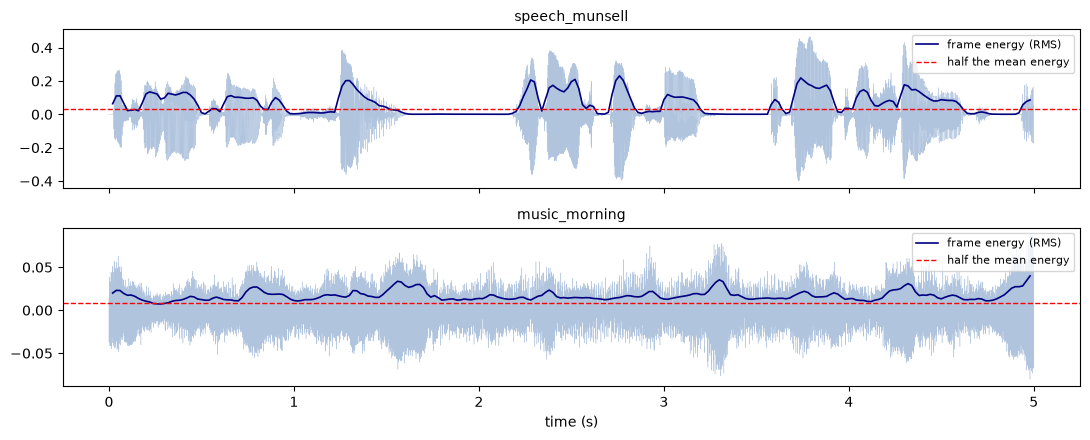

In [8]:
FRAME, HOP = 0.040, 0.020        # 40 ms frames with a 20 ms hop, as in the book's section on time

def frames(x, sr):
    """Overlapping frames of the signal as rows of a matrix."""
    n, h = int(FRAME * sr), int(HOP * sr)
    starts = h * np.arange(1 + (len(x) - n) // h)
    return x[starts[:, None] + np.arange(n)]

def rms(f):
    """Energy (root mean square) of each frame."""
    return np.sqrt((f ** 2).mean(axis=1))

def zcr(f):
    """Zero-crossing rate of each frame: share of neighboring samples with different signs."""
    return (np.diff(np.sign(f), axis=1) != 0).mean(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True)
for ax, name in zip(axes, ["speech_munsell", "music_morning"]):
    sr, x = load_audio(name)
    x = x[: 5 * sr]
    t = np.arange(len(x)) / sr
    energy = rms(frames(x, sr))
    ax.plot(t, x, lw=0.3, color="lightsteelblue")
    ax.plot(HOP * np.arange(len(energy)) + FRAME / 2, energy, color="navy", lw=1.2, label="frame energy (RMS)")
    ax.axhline(0.5 * energy.mean(), color="red", ls="--", lw=1, label="half the mean energy")
    ax.set_title(name, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
axes[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

The energy of the speech recording drops below half its mean between words and phrases. The
music stays above it. We turn this into two numbers per 2-second segment: the **share of
low-energy frames** (frames below half the mean energy of the segment) and the **variation of the
zero-crossing rate** (its standard deviation over the frames).

In [9]:
SEGMENT = 2.0                    # seconds per labeled example

def segment_features(x, sr):
    """Per segment: share of low-energy frames and standard deviation of the zero-crossing rate."""
    n = int(SEGMENT * sr)
    feats = []
    for start in range(0, len(x) - n + 1, n):
        f = frames(x[start:start + n], sr)
        e = rms(f)
        feats.append([(e < 0.5 * e.mean()).mean(), zcr(f).std()])
    return np.array(feats)

X, y, source = [], [], []
for name, (_, label) in AUDIO.items():
    sr, x = load_audio(name)
    F = segment_features(x, sr)
    X.append(F); y += [label] * len(F); source += [name] * len(F)
X, y, source = np.vstack(X), np.array(y), np.array(source)

print_table([[name, label, (source == name).sum(), X[source == name, 0].mean(), X[source == name, 1].mean()]
             for name, (_, label) in AUDIO.items()],
            headers=["Recording", "Class", "Segments", "Low-energy share (mean)", "ZCR variation (mean)"],
            floatfmt=("", "", "", ".2f", ".3f"))

| Recording           | Class   |   Segments |   Low-energy share (mean) |   ZCR variation (mean) |
|:--------------------|:--------|-----------:|--------------------------:|-----------------------:|
| speech_munsell      | speech  |         15 |                      0.42 |                  0.173 |
| speech_tucker       | speech  |         15 |                      0.37 |                  0.134 |
| speech_hedrick      | speech  |         15 |                      0.39 |                  0.138 |
| music_morning       | music   |         15 |                      0.03 |                  0.025 |
| music_mountain_king | music   |         15 |                      0.20 |                  0.015 |
| music_goldberg_aria | music   |         15 |                      0.14 |                  0.013 |

A fair test uses recordings that the classifier has never heard. We train a decision tree on two
readers and two music pieces and test it on the third reader and the third piece.

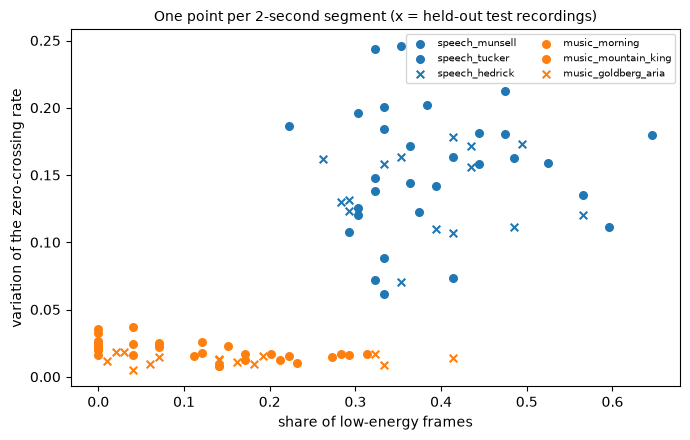

**Learned tree:**

```text
|--- zcr_variation <= 0.05
|   |--- class: music
|--- zcr_variation >  0.05
|   |--- class: speech
```

| Test segments | predicted speech | predicted music |
|---|---|---|
| speech (speech_hedrick) | 15 | 0 |
| music (music_goldberg_aria) | 0 | 15 |

Accuracy on the held-out recordings: **100%** of 30 segments.

In [10]:
TEST = ["speech_hedrick", "music_goldberg_aria"]
test = np.isin(source, TEST)

tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X[~test], y[~test])
pred = tree.predict(X[test])
cm = confusion_matrix(y[test], pred, labels=["speech", "music"])

fig, ax = plt.subplots(figsize=(7, 4.5))
for name in AUDIO:
    m = source == name
    ax.scatter(X[m, 0], X[m, 1], marker="x" if name in TEST else "o", s=30,
               color="tab:blue" if AUDIO[name][1] == "speech" else "tab:orange", label=name)
ax.set_xlabel("share of low-energy frames")
ax.set_ylabel("variation of the zero-crossing rate")
ax.legend(fontsize=7, ncol=2)
ax.set_title("One point per 2-second segment (x = held-out test recordings)", fontsize=10)
plt.tight_layout()
plt.show()

rules = export_text(tree, feature_names=["low_energy_share", "zcr_variation"])
display_md(
    f"**Learned tree:**\n\n```text\n{rules}```\n\n"
    f"| Test segments | predicted speech | predicted music |\n|---|---|---|\n"
    f"| speech ({TEST[0]}) | {cm[0, 0]} | {cm[0, 1]} |\n| music ({TEST[1]}) | {cm[1, 0]} | {cm[1, 1]} |\n\n"
    f"Accuracy on the held-out recordings: **{(pred == y[test]).mean():.0%}** of {test.sum()} segments."
)

The tree needs only one of the two features and one threshold, and the rule is readable. The
low-energy shares overlap: the piano piece and quiet orchestra passages also have soft frames.
The zero-crossing rate of speech, however, varies far more than that of music, because voiced
sounds, hissing consonants, and pauses alternate. The predicted labels "speech" and "music" are text, so they
become metadata and return to the keyword path of demo ch09-01. They also decide which analysis
follows: speech goes to transcription, music to genre classification.

The weak point is the hand-crafted feature. Someone had to know that pauses and zero crossings
separate these two classes. No one can design such a feature for "Taj Mahal" versus "other white
buildings with domes".

## 6. Learned Features: A Pretrained Network

Neural networks learn the features themselves. ResNet-50 was trained on the 1,000 classes of
ImageNet. Its last layer turns a 2048-dimensional vector into class scores; the vector itself,
the output of the second-to-last layer, describes the image. These vectors were the first learned
image embeddings. We compute them for the collection and compare all pairs by cosine similarity.

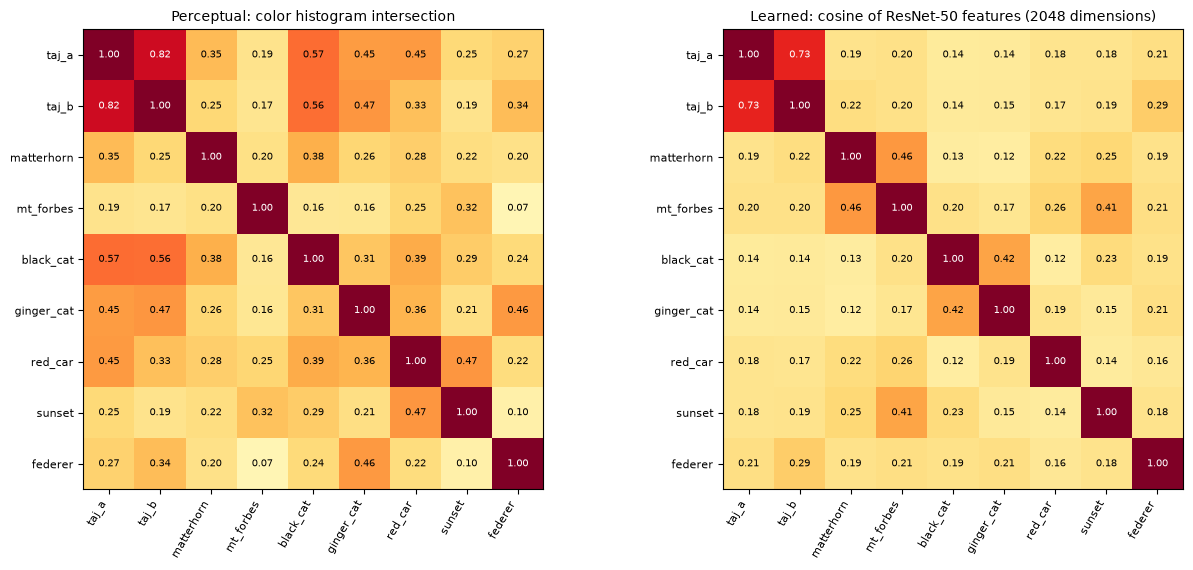

| Image 1    | Image 2    |   Histogram intersection |   ResNet-50 cosine |
|:-----------|:-----------|-------------------------:|-------------------:|
| red_car    | sunset     |                     0.47 |               0.14 |
| black_cat  | ginger_cat |                     0.31 |               0.42 |
| black_cat  | taj_a      |                     0.57 |               0.14 |
| matterhorn | mt_forbes  |                     0.20 |               0.46 |

In [11]:
processor = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
resnet = ResNetForImageClassification.from_pretrained("microsoft/resnet-50").eval()

with torch.no_grad():
    batch = processor(images=list(images.values()), return_tensors="pt")
    pooled = resnet.resnet(**batch).pooler_output           # second-to-last layer: (9, 2048, 1, 1)
    probs = resnet.classifier(pooled).softmax(dim=-1).numpy()
emb = pooled.flatten(1).numpy()
emb /= np.linalg.norm(emb, axis=1, keepdims=True)
S_cnn = emb @ emb.T

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
show_matrix(S_hist, "Perceptual: color histogram intersection", axes[0])
show_matrix(S_cnn, f"Learned: cosine of ResNet-50 features ({emb.shape[1]} dimensions)", axes[1])
plt.tight_layout()
plt.show()

cnn = lambda p, q: S_cnn[names.index(p), names.index(q)]
print_table([[p, q, pair(p, q), cnn(p, q)] for p, q in
             [("red_car", "sunset"), ("black_cat", "ginger_cat"), ("black_cat", "taj_a"), ("matterhorn", "mt_forbes")]],
            headers=["Image 1", "Image 2", "Histogram intersection", "ResNet-50 cosine"], floatfmt=("", "", ".2f", ".2f"))

The learned features reverse the perceptual comparisons. The two cats are now close, the car and
the sunset far apart. The two mountains are close although their histograms differ. The two
scales are not the same (an intersection is not a cosine), so the order within each matrix
carries the information, not the absolute values.

### The labels are claims

The same network also predicts a class for each photo. These labels are what a recognition
branch returns.

In [12]:
labels = resnet.config.id2label
rows = []
for i, name in enumerate(names):
    top = np.argsort(-probs[i])[:2]
    rows.append([name, IMAGES[name][2]] + [f"{labels[int(k)].split(',')[0]} ({probs[i][k]:.0%})" for k in top])
print_table(rows, headers=["Image", "Actual content", "Label 1 (confidence)", "Label 2 (confidence)"])

| Image      | Actual content   | Label 1 (confidence)   | Label 2 (confidence)   |
|:-----------|:-----------------|:-----------------------|:-----------------------|
| taj_a      | Taj Mahal        | mosque (100%)          | palace (0%)            |
| taj_b      | Taj Mahal        | mosque (89%)           | palace (5%)            |
| matterhorn | mountain         | alp (98%)              | valley (1%)            |
| mt_forbes  | mountain         | volcano (100%)         | alp (0%)               |
| black_cat  | cat              | Egyptian cat (65%)     | quilt (8%)             |
| ginger_cat | cat              | tiger cat (58%)        | tabby (23%)            |
| red_car    | car              | grille (97%)           | sports car (3%)        |
| sunset     | sunset           | balloon (70%)          | radio telescope (7%)   |
| federer    | tennis player    | racket (42%)           | volleyball (18%)       |

Some labels fit: "alp" for the Matterhorn, "Egyptian cat" and "tiger cat" (ImageNet's names for
coat patterns) for the cats, "racket" for Federer. Others are confident and wrong. Mt. Forbes in
alpenglow becomes a "volcano", the setting sun a "balloon", the Taj Mahal a "mosque". ImageNet has
no class "mausoleum" or "sunset", and a classifier knows only the classes it was trained on, so it
picks the most similar one. The car becomes a "grille": the network sees a center crop, which
shows mostly the front of the car. A confidence value expresses how strongly the model favors a
label among its own classes, not how often such labels are correct. Before turning
labels into metadata, a threshold per label must be chosen on an evaluation against ground truth,
as Chapter 2 does for text classifiers.

## Payoff: Query by Example

The first use of perceptual features in the book is similarity search: the query is an example
image, and the system returns the closest item. We run this search for every photo of the
collection, once with color histograms and once with ResNet-50 features, and check whether the
nearest neighbor shows the same kind of content.

In [13]:
def nearest(S, i):
    """Index of the most similar other item in row i of a similarity matrix."""
    row = S[i].copy()
    row[i] = -np.inf
    return int(np.argmax(row))

kind = lambda name: IMAGES[name][2]
rows, hits = [], {"hist": 0, "cnn": 0}
for i, name in enumerate(names):
    nh, nc = names[nearest(S_hist, i)], names[nearest(S_cnn, i)]
    has_pair = sum(kind(n) == kind(name) for n in names) > 1
    mark = lambda n: ("yes" if kind(n) == kind(name) else "no") if has_pair else "(no partner)"
    hits["hist"] += kind(nh) == kind(name)
    hits["cnn"] += kind(nc) == kind(name)
    rows.append([name, nh, mark(nh), nc, mark(nc)])
print_table(rows, headers=["Query image", "Nearest by histogram", "Same kind?", "Nearest by ResNet-50", "Same kind?"])

n_pairs = sum(sum(kind(n) == kind(m) for n in names) > 1 for m in names)
display_md(f"Same kind as the query: **{hits['hist']} of {n_pairs}** by histogram, **{hits['cnn']} of {n_pairs}** by ResNet-50 features.")

| Query image   | Nearest by histogram   | Same kind?   | Nearest by ResNet-50   | Same kind?   |
|:--------------|:-----------------------|:-------------|:-----------------------|:-------------|
| taj_a         | taj_b                  | yes          | taj_b                  | yes          |
| taj_b         | taj_a                  | yes          | taj_a                  | yes          |
| matterhorn    | black_cat              | no           | mt_forbes              | yes          |
| mt_forbes     | sunset                 | no           | matterhorn             | yes          |
| black_cat     | taj_a                  | no           | ginger_cat             | yes          |
| ginger_cat    | taj_b                  | no           | black_cat              | yes          |
| red_car       | sunset                 | (no partner) | mt_forbes              | (no partner) |
| sunset        | red_car                | (no partner) | mt_forbes              | (no partner) |
| federer       | ginger_cat             | (no partner) | taj_b                  | (no partner) |

Same kind as the query: **2 of 6** by histogram, **6 of 6** by ResNet-50 features.

By histogram, the black cat finds the Taj Mahal, the red car finds the sunset, and the tennis
photo, with its green lawn, finds the ginger kitten in the grass. With learned features, the
query "more pictures like this black cat" returns the ginger kitten. Learned features
close a part of the semantic gap that hand-crafted perceptual features leave open, and they do
it without any metadata.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">From signal statistics to learned descriptions</strong><br>
Raw data does not relate similar content. Perceptual features such as color histograms do, but only for content that looks alike: a red car matches a sunset. A classifier turns features into labels, which become metadata, but hand-crafted features work only for narrow tasks. Learned features of a neural network relate photos by what they show, and its labels are claims that must be evaluated like any other metadata.
</div>

## Summary

- The raw level preserves content but does not relate it: two photos of one building, taken 99
  seconds apart, share almost no pixel values.
- Perceptual features describe how content looks. A color histogram is the counterpart of a term
  vector; it is stable under translation, rotation, scale, and moderate noise, but not under a
  change of lighting.
- Perceptual similarity is not semantic similarity: the red car matches the sunset, and the black
  cat matches the Taj Mahal better than the ginger cat.
- A decision tree on two hand-crafted frame features separates speech from music on recordings
  it has never heard. Its labels become metadata.
- A pretrained network learns features that relate images by content. Its labels come from a
  fixed class list and are claims, not facts.

## Try it yourself

1. Change `BINS` to 2 and to 8 and rerun sections 3 and 4. How do the intersections of the car
   and the sunset, and of the two cats, change?
2. Replace the lighting change by `ImageEnhance.Color(img).enhance(0.3)` (less saturated colors).
   Which other changes would a person ignore but the histogram not?
3. Swap the test recordings in `TEST`, for example `["speech_tucker", "music_mountain_king"]`.
   Does the learned threshold stay the same? To listen to a clip, run
   `sr, x = load_audio("music_goldberg_aria")` and then `IPython.display.Audio(x, rate=sr)`.
4. Add your own photo to `images` (for example `images["mine"] = Image.open("my_photo.jpg").convert("RGB")`)
   and rerun section 6 and the payoff. Which image is its nearest neighbor by each feature?